Hyperparameter selection via cross validation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import re
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent          # analysis/ -> FitNMF/
# or, to work from any subfolder: ROOT = find_repo_root()   (function from before)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
real_data_cv = pd.read_csv('/Users/arimaite/Documents/GitHub/FitNMF/results/cross_validation_results/ZH_2021_2024/cross_validation_summary_snv.csv')
simulated_data_cv = pd.read_csv('/Users/arimaite/Documents/GitHub/FitNMF/results/cross_validation_results/simulations/cross_validation_summary_snv.csv',  header=0)

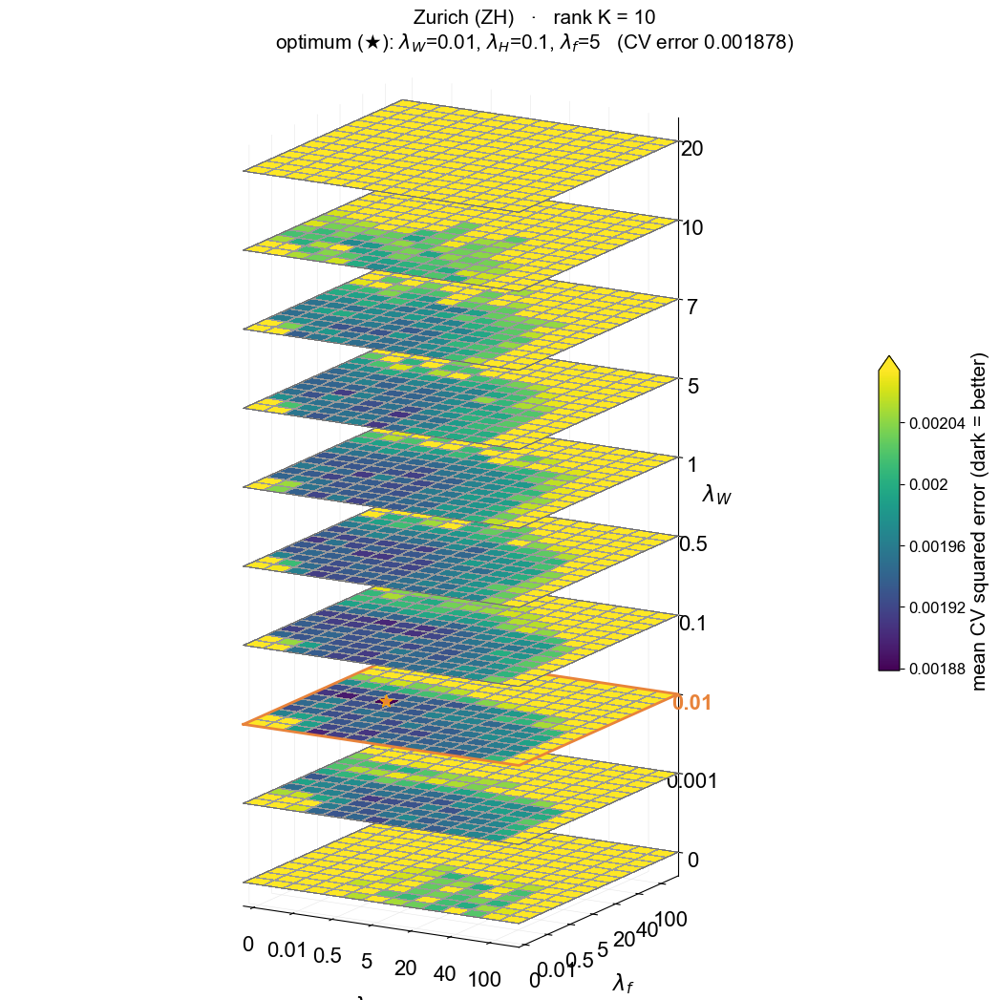

location            ZH
n_variants          10
lambda_w          0.01
lambda_h           0.1
lambda_f           5.0
mean_error    0.001878
std_error      0.00008
Name: 15680, dtype: object


In [9]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

ORANGE = '#E8833A'
LABEL = {'lambda_w': r'$\lambda_W$', 'lambda_h': r'$\lambda_H$', 'lambda_f': r'$\lambda_f$'}


def plot_cv_stacked(summ, location='ZH', rank=10, stack='lambda_w', rule='1sd', n_sd=1, priority=None,
                    vmax_quantile=0.5, cmap='viridis', gap=2.0, alpha=1, grid_color='0.6', grid_lw=0.3,
                    elev=15, azim=-60, figsize=(10, 11), title=None, save=True, show=True):
    """Stacked 3D heatmaps of the mean CV error: one horizontal layer for EVERY value of `stack`
       (default lambda_W); each layer is a heatmap over the other two lambdas
       (lambda_W layers -> lambda_H on x, lambda_f on y).
       Selection (orange star):
         rule='min' -> combination with the lowest mean CV error.
         rule='1sd' -> among all combinations with mean_error <= min + n_sd * std_error(min combination),
                       the most strongly regularised one:
                       priority=None  -> largest total regularisation = sum of grid positions of
                                         (lambda_w, lambda_h, lambda_f) (scale-free); ties -> lower error.
                       priority=[...] -> lexicographic, e.g. ['lambda_f', 'lambda_h', 'lambda_w'].
         With rule='1sd' the minimum is also marked (white circle).
       Colour = shared LINEAR scale from the minimum error to the `vmax_quantile` of all errors (dark = better).
       `gap` = vertical distance between layers (larger -> more space, taller box)."""
    s = summ[(summ['location'] == location) & (summ['n_variants'] == rank)].dropna(subset=['mean_error'])
    if s.empty:
        raise ValueError(f"{location}: no results for rank {rank} "
                         f"(available ranks: {sorted(summ.loc[summ['location'] == location, 'n_variants'].unique())})")
    lams = ['lambda_w', 'lambda_h', 'lambda_f']

    # ---- selection -------------------------------------------------------------------------------
    best_min = s.loc[s['mean_error'].idxmin()]
    if rule == 'min':
        best, thr, n_within = best_min, np.nan, 1
    elif rule == '1sd':
        if 'std_error' not in s.columns:
            raise ValueError("rule='1sd' needs a 'std_error' column (SD of the CV error across folds)")
        thr = best_min['mean_error'] + n_sd * best_min['std_error']
        cand = s[s['mean_error'] <= thr].copy()
        if priority is None:
            pos = sum(cand[k].map({v: i for i, v in enumerate(sorted(s[k].unique()))}) for k in lams)
            cand = cand.assign(_score=pos).sort_values(['_score', 'mean_error'], ascending=[False, True])
        else:
            cand = cand.sort_values(list(priority) + ['mean_error'],
                                    ascending=[False] * len(priority) + [True])
        best, n_within = cand.iloc[0], len(cand)
    else:
        raise ValueError("rule must be 'min' or '1sd'")

    xk, yk = [k for k in lams if k != stack]
    x_vals = sorted(s[xk].unique())
    y_vals = sorted(s[yk].unique())
    z_vals = sorted(s[stack].unique())                          # all layers
    nx, ny, nz = len(x_vals), len(y_vals), len(z_vals)

    vmin = s['mean_error'].min()
    vmax = max(s['mean_error'].quantile(vmax_quantile), vmin + 1e-12)
    norm = Normalize(vmin=vmin, vmax=vmax, clip=True)          # linear colour scale
    cm = plt.get_cmap(cmap)

    Xe, Ye = np.meshgrid(np.arange(nx + 1) - 0.5, np.arange(ny + 1) - 0.5)   # cell edges

    with mpl.rc_context({'font.family': 'sans-serif',
                         'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                         'mathtext.fontset': 'dejavusans'}):
        fig = plt.figure(figsize=figsize)
        ax = fig.add_axes([-0.05, 0.0, 0.92, 0.92], projection='3d', computed_zorder=False)
        ax.set_proj_type('ortho')

        for k, zv in enumerate(z_vals):
            sl = s[s[stack] == zv]
            grid = (sl.pivot_table(index=yk, columns=xk, values='mean_error', aggfunc='min')
                      .reindex(index=y_vals, columns=x_vals))
            colors = cm(norm(grid.values))
            colors[..., 3] = np.where(np.isnan(grid.values), 0.0, alpha)    # missing cells transparent
            fc = np.zeros((ny + 1, nx + 1, 4)); fc[:ny, :nx] = colors
            surf = ax.plot_surface(Xe, Ye, np.full(Xe.shape, k * gap), facecolors=fc, rstride=1, cstride=1,
                                   shade=False, linewidth=grid_lw, antialiased=False, zorder=k)
            surf.set_edgecolor(grid_color)                                  # gray cell grid
            is_best = (zv == best[stack])                                   # highlight the selected layer
            ax.plot([-0.5, nx - 0.5, nx - 0.5, -0.5, -0.5], [-0.5, -0.5, ny - 0.5, ny - 0.5, -0.5],
                    [k * gap] * 5, color=ORANGE if is_best else '0.35', lw=2.0 if is_best else 0.5,
                    zorder=k + 0.5)

        if rule == '1sd':                                                   # minimum: white circle
            ax.scatter([x_vals.index(best_min[xk])], [y_vals.index(best_min[yk])],
                       [z_vals.index(best_min[stack]) * gap],
                       marker='o', s=50, color='white', edgecolor='black', linewidth=1.0,
                       depthshade=False, zorder=nz + 9)
        ax.scatter([x_vals.index(best[xk])], [y_vals.index(best[yk])], [z_vals.index(best[stack]) * gap],
                   marker='*', s=100, color=ORANGE, edgecolor='orange', linewidth=0.8,
                   depthshade=False, zorder=nz + 10)          # always on top

        def _ticks(vals, nmax=8):
            step = max(1, int(np.ceil(len(vals) / nmax)))
            idx = list(range(0, len(vals), step))
            return idx, [f"{vals[i]:g}" for i in idx]
        xi, xl = _ticks(x_vals); yi, yl = _ticks(y_vals)
        ax.set_xticks(xi); ax.set_xticklabels(xl, fontsize=16)
        ax.set_yticks(yi); ax.set_yticklabels(yl, fontsize=16)
        ax.set_zticks([k * gap for k in range(nz)])
        ax.set_zticklabels([f"{v:g}" for v in z_vals], fontsize=16)
        for lab, zv in zip(ax.get_zticklabels(), z_vals):
            if zv == best[stack]:
                lab.set_color(ORANGE); lab.set_fontweight('bold')
        for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):
            a_.set_rotate_label(False)
        ax.set_xlabel(LABEL[xk], fontsize=16, labelpad=12)
        ax.set_ylabel(LABEL[yk], fontsize=16, labelpad=10)
        ax.set_zlabel(LABEL[stack], fontsize=16, labelpad=10)
        ax.set_xlim(-0.5, nx - 0.5); ax.set_ylim(-0.5, ny - 0.5)
        z_lo, z_hi = -0.3 * gap, (nz - 0.7) * gap
        ax.set_zlim(z_lo, z_hi)
        for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):
            a_.set_pane_color((1, 1, 1, 0)); a_._axinfo['grid'].update(color='0.9', linewidth=0.4)
        ax.set_box_aspect((1, ny / nx, (z_hi - z_lo) / nx * 1.8))
        ax.view_init(elev=elev, azim=azim)

        sm = mpl.cm.ScalarMappable(norm=norm, cmap=cm)
        cb = fig.colorbar(sm, cax=fig.add_axes([0.86, 0.32, 0.022, 0.30]),
                          extend='max' if vmax < s['mean_error'].max() else 'neither')
        cb.ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(6))
        cb.ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.3g}"))
        cb.ax.tick_params(labelsize=12)
        cb.set_label('mean CV squared error (dark = better)', fontsize=15)

        sel = (f"$\\lambda_W$={best['lambda_w']:g}, $\\lambda_H$={best['lambda_h']:g}, "
               f"$\\lambda_f$={best['lambda_f']:g}   (CV error {best['mean_error']:.4g})")
        if rule == '1sd':
            sub = (f"\nselected ($\\bigstar$, largest within {n_sd:g} SD of min): " + sel +
                   f"\nminimum ($\\bigcirc$): $\\lambda_W$={best_min['lambda_w']:g}, "
                   f"$\\lambda_H$={best_min['lambda_h']:g}, $\\lambda_f$={best_min['lambda_f']:g}   "
                   f"(CV error {best_min['mean_error']:.4g} ± {best_min['std_error']:.2g})")
        else:
            sub = "\noptimum ($\\bigstar$): " + sel
        fig.suptitle((title or f"{location}   ·   rank K = {rank}") + sub, fontsize=15, y=0.95)
        if save:
            tag = f"_{rule}" if rule != 'min' else ''
            fig.savefig(f"../results/cross_validation_results/ZH_2021_2024/cv_stacked_{stack}_{location}_rank{rank}{tag}.png", dpi=300, bbox_inches='tight', pad_inches=0.3)
            fig.savefig(f"../results/cross_validation_results/ZH_2021_2024/cv_stacked_{stack}_{location}_rank{rank}{tag}.pdf", bbox_inches='tight', pad_inches=0.3)
        if show:
            plt.show()
    return best


if __name__ == '__main__':
    best = plot_cv_stacked(real_data_cv, location='ZH', rank=10, stack='lambda_w', rule='min',
                           title='Zurich (ZH)   ·   rank K = 10')
    print(best)


# Number of variants selection - REAL DATA

/var/folders/0b/q8fnqcm16vx8w3f6xx02w7cc0000gr/T/ipykernel_97879/3638404969.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=10)


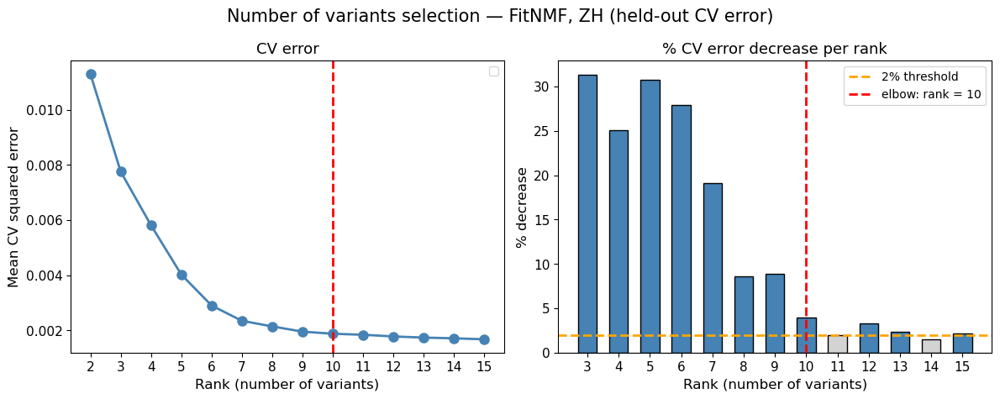


Fitness NMF:  minimum = 15,  elbow (2%) = 10
 Rank     CV error          SD   Decrease %     λ_W    λ_H    λ_f
------------------------------------------------------------------
    2       0.0113     0.00023            —       5     30     10
    3     0.007758     0.00025        31.3%       1    100      0
    4     0.005815     0.00016        25.0%     0.1      1    0.5
    5    0.0040265     9.4e-05        30.8%     0.1     10      5
    6    0.0029031     5.8e-05        27.9%    0.01      0      5
    7    0.0023478     6.9e-05        19.1%     0.1     10      5
    8    0.0021449     8.4e-05         8.6%    0.01    0.1      5
    9    0.0019554     5.9e-05         8.8%    0.01    0.5      5
   10    0.0018784       8e-05         3.9%    0.01    0.1      5  ← elbow
   11    0.0018415     8.3e-05         2.0%     0.1    0.5  0.001
   12    0.0017809     7.2e-05         3.3%     0.1      1    0.1
   13    0.0017386     6.6e-05         2.4%    0.01    0.5    0.1
   14    0.0017135  

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# real_data_cv: columns location, n_variants, lambda_w, lambda_h, lambda_f, mean_error, std_error
LOCATION = 'ZH'
THR_PCT  = 2.0    # % decrease threshold (elbow heuristic, shown for comparison)

d = real_data_cv[real_data_cv['location'] == LOCATION].dropna(subset=['mean_error'])

# for every rank keep the best lambda combination (profile CV error over lambda_W, lambda_H, lambda_f)
best   = d.loc[d.groupby('n_variants')['mean_error'].idxmin()].sort_values('n_variants')
ranks  = best['n_variants'].values
errors = best['mean_error'].values
sds    = best['std_error'].values
rel    = -np.diff(errors) / errors[:-1] * 100           # % decrease from rank r_i to r_{i+1}

# ── rank selection ───────────────────────────────────────────────────────────
i_min      = np.argmin(errors)
min_rank   = ranks[i_min]                                # lowest CV error
below      = np.where(rel < THR_PCT)[0]
elbow_rank = ranks[below[0]] if len(below) > 0 else None # last rank reached with a >= 5% decrease

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# ── CV error vs rank ─────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(ranks, errors, marker='o', color='steelblue', markersize=8, linewidth=2)
ax.axvline(elbow_rank, color='red', linestyle='--', linewidth=2)
ax.set_title('CV error', fontsize=13)
ax.set_xlabel('Rank (number of variants)', fontsize=12)
ax.set_ylabel('Mean CV squared error', fontsize=12)
ax.set_xticks(ranks)
ax.tick_params(labelsize=11)
ax.legend(fontsize=10)

# ── relative decrease ────────────────────────────────────────────────────────
ax = axes[1]
ax.bar(ranks[1:], rel, color=np.where(rel >= THR_PCT, 'steelblue', 'lightgrey'),
       width=0.6, edgecolor='black', linewidth=1)
ax.axhline(THR_PCT, color='orange', linestyle='--', linewidth=2, label=f'{THR_PCT:g}% threshold')
ax.axhline(0, color='black', linewidth=0.8)
if elbow_rank is not None:
    ax.axvline(elbow_rank, color='red', linestyle='--', linewidth=2, label=f'elbow: rank = {elbow_rank}')
ax.set_title('% CV error decrease per rank', fontsize=13)
ax.set_xlabel('Rank (number of variants)', fontsize=12)
ax.set_ylabel('% decrease', fontsize=12)
ax.set_xticks(ranks[1:])
ax.tick_params(labelsize=11)
ax.legend(fontsize=10)

plt.suptitle(f'Number of variants selection — FitNMF, {LOCATION} (held-out CV error)', fontsize=15)
plt.tight_layout()
plt.savefig(f'../results/cross_validation_results/ZH_2021_2024/cv_rank_selection_{LOCATION}.png', dpi=300, bbox_inches='tight')
plt.savefig(f'../results/cross_validation_results/ZH_2021_2024/cv_rank_selection_{LOCATION}.pdf', bbox_inches='tight')
plt.show()

# ── Print ────────────────────────────────────────────────────────────────────
print(f"\nFitness NMF:  minimum = {min_rank},  elbow ({THR_PCT:g}%) = {elbow_rank}")
print(f"{'Rank':>5}  {'CV error':>11}  {'SD':>10}  {'Decrease %':>11}  {'λ_W':>6} {'λ_H':>6} {'λ_f':>6}")
print("-" * 66)
for i, (_, r) in enumerate(best.iterrows()):
    dec  = f"{rel[i-1]:.1f}%" if i > 0 else "—"
    tags = [t for t, rr in (('min', min_rank),  ('elbow', elbow_rank)) if r['n_variants'] == rr]
    print(f"{int(r['n_variants']):>5}  {r['mean_error']:>11.5g}  {r['std_error']:>10.2g}  {dec:>11}  "
          f"{r['lambda_w']:>6g} {r['lambda_h']:>6g} {r['lambda_f']:>6g}" + (f"  ← {', '.join(tags)}" if tags else ""))

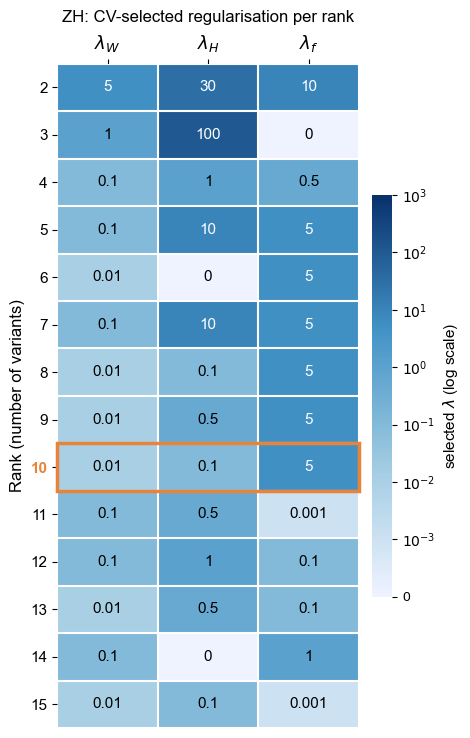

In [11]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap

# real_data_cv: columns location, n_variants, lambda_w, lambda_h, lambda_f, mean_error, std_error
LOCATION = 'ZH'
SEL_RANK = 10          # rank chosen for the paper (row is highlighted); None -> no highlight
FLOOR    = 1e-4       # lambda = 0 is drawn at this value (lightest colour) and labelled "0"
LAMS     = ['lambda_w', 'lambda_h', 'lambda_f']
COLLAB   = [r'$\lambda_W$', r'$\lambda_H$', r'$\lambda_f$']

d = real_data_cv[real_data_cv['location'] == LOCATION].dropna(subset=['mean_error'])

# best (lowest mean CV error) lambda combination for every rank
best  = d.loc[d.groupby('n_variants')['mean_error'].idxmin()].sort_values('n_variants').reset_index(drop=True)
ranks = best['n_variants'].astype(int).values
vals  = best[LAMS].values.astype(float)

# colour = log10(lambda), one shared scale for the three columns
z    = np.log10(np.maximum(vals, FLOOR))
vmax = np.log10(max(d[LAMS].values.max(), FLOOR * 10))
norm = Normalize(np.log10(FLOOR), vmax)
cmap = LinearSegmentedColormap.from_list('lam', ['#EFF3FF', '#9ECAE1', '#4292C6', '#08306B'])  # same as best-lambda heatmap: light = 0, dark = strong

with mpl.rc_context({'font.family': 'sans-serif',
                     'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                     'mathtext.fontset': 'dejavusans'}):
    fig, ax = plt.subplots(figsize=(4.8, 0.42 * len(ranks) + 1.6))
    im = ax.imshow(z, cmap=cmap, norm=norm, aspect='auto')

    # cell labels: actual lambda value, white on dark cells
    for i in range(len(ranks)):
        for j in range(len(LAMS)):
            v = vals[i, j]
            ax.text(j, i, f"{v:g}", ha='center', va='center', fontsize=11,
                    color='white' if norm(z[i, j]) > 0.6 else 'black')

    # white grid between cells
    ax.set_xticks(np.arange(len(LAMS) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(ranks) + 1) - 0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=1.5)
    ax.tick_params(which='minor', length=0)

    # highlight the selected rank
    if SEL_RANK is not None and SEL_RANK in ranks:
        i_sel = int(np.where(ranks == SEL_RANK)[0][0])
        ax.add_patch(plt.Rectangle((-0.5, i_sel - 0.5), len(LAMS), 1, fill=False,
                                   edgecolor='#E8833A', linewidth=2.5, clip_on=False, zorder=5))

    ax.set_xticks(range(len(LAMS))); ax.set_xticklabels(COLLAB, fontsize=13)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(ranks))); ax.set_yticklabels(ranks, fontsize=11)
    for lab, r in zip(ax.get_yticklabels(), ranks):
        if r == SEL_RANK:
            lab.set_color('#E8833A'); lab.set_fontweight('bold')
    ax.set_ylabel('Rank (number of variants)', fontsize=12)
    for sp in ax.spines.values():
        sp.set_visible(False)

    cb = fig.colorbar(im, ax=ax, fraction=0.06, pad=0.04)
    ticks = np.arange(np.ceil(np.log10(FLOOR)), np.floor(vmax) + 1)
    cb.set_ticks(ticks)
    cb.set_ticklabels(['0' if t == np.log10(FLOOR) else f"$10^{{{int(t)}}}$" for t in ticks])
    cb.ax.tick_params(labelsize=10)
    cb.set_label(r'selected $\lambda$ (log scale)', fontsize=11)
    cb.outline.set_visible(False)

    ax.set_title(f'{LOCATION}: CV-selected regularisation per rank', fontsize=12, pad=30)
    plt.tight_layout()
    plt.savefig(f'../results/cross_validation_results/ZH_2021_2024/lambda_by_rank_{LOCATION}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'../results/cross_validation_results/ZH_2021_2024/lambda_by_rank_{LOCATION}.pdf', bbox_inches='tight')
    plt.show()

# Simulated data

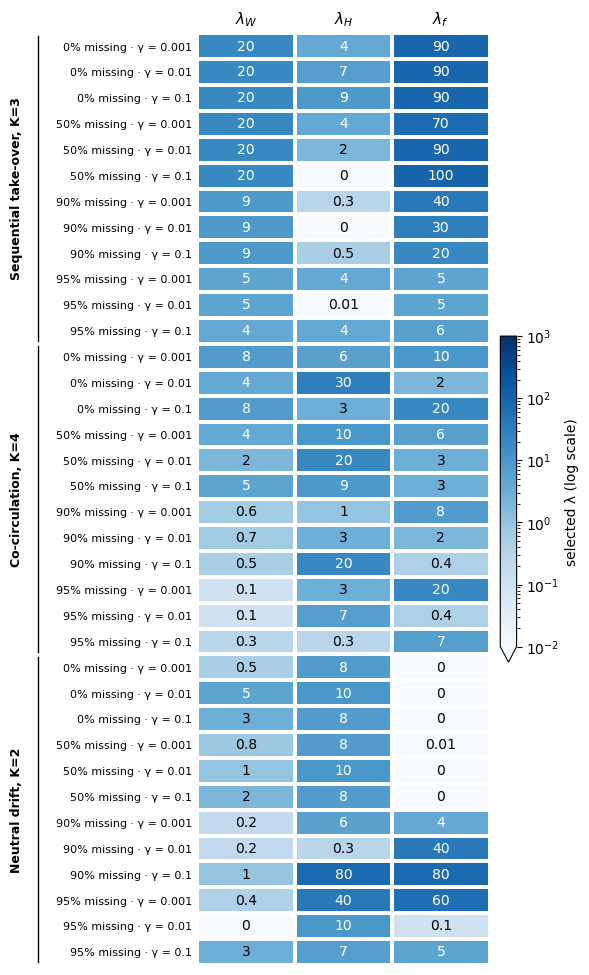

In [12]:
import re
from matplotlib.colors import LogNorm
TRUE_RANK = {'delta': 3, 'omicron': 4, 'drift': 2}

GAMMA   = {1: 0.001, 2: 0.01, 3: 0.1}                       # disp1..3    (as assumed earlier: check!)
MISSING = {1: 0.0, 6: 0.5, 10: 0.9, 11: 0.95}               # missing_1/6/10/11
SCEN_LABEL = {'delta': 'Sequential take-over', 'omicron': 'Co-circulation', 'drift': 'Neutral drift'}
def true_rank(name):
    for key, r in TRUE_RANK.items():
        if key in name:
            return r
    raise ValueError(f"cannot infer the scenario (delta / omicron / drift) from '{name}'")

def best_lambda_table(summ):
    """CV-optimal (lambda_w, lambda_h, lambda_f) at the true rank for every simulated dataset."""
    rows = []
    for sim in sorted(summ.sim.unique()):
        r = true_rank(sim)
        s = summ[(summ.sim == sim) & (summ.n_variants == r)]
        if s.empty:
            continue
        best_row = s.loc[s.mean_error.idxmin()]
        m = re.match(r'disp(\d+)_missing_(\d+)_', sim)
        key = next(k for k in TRUE_RANK if k in sim)
        rows.append(dict(sim=sim, scen=key, k=r, gamma=GAMMA[int(m.group(1))], miss=MISSING[int(m.group(2))],
                         lw=best_row.lambda_w, lh=best_row.lambda_h, lf=best_row.lambda_f))
    tab = pd.DataFrame(rows)
    tab['o'] = tab.scen.map({k: i for i, k in enumerate(TRUE_RANK)})      # delta, omicron, drift
    return tab.sort_values(['o', 'miss', 'gamma']).reset_index(drop=True)


def plot_optimal_lambda_table(summ, save=True, vmin=1e-2, vmax=1e3, bracket_x=-1.1):
    tab = best_lambda_table(summ)
    vals = tab[['lw', 'lh', 'lf']].to_numpy(float)
    norm = LogNorm(vmin=vmin, vmax=vmax)
    n = len(tab)

    fig, ax = plt.subplots(figsize=(4.6, 0.3 * n + 1.3))
    mesh = ax.pcolormesh(np.clip(vals, vmin, None), cmap='Blues', norm=norm, edgecolors='white', linewidth=1.5)
    ax.set_ylim(n, 0)
    for i in range(n):
        for j in range(3):
            v = vals[i, j]
            ax.text(j + 0.5, i + 0.5, f"{v:g}", ha='center', va='center', fontsize=10,
                    color='white' if norm(max(v, vmin)) > 0.5 else 'black')

    ax.set_yticks(np.arange(n) + 0.5)
    ax.set_yticklabels([f"{m*100:.0f}% missing · γ = {g:g}" for m, g in zip(tab.miss, tab.gamma)], fontsize=8)
    ax.set_xticks([0.5, 1.5, 2.5]); ax.set_xticklabels([r'$\lambda_W$', r'$\lambda_H$', r'$\lambda_f$'], fontsize=11)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

    #trans = ax.get_yaxis_transform()                        # x: axes fraction, y: data
    fig.canvas.draw()                                       # tick labels need a draw to have a size
    renderer = fig.canvas.get_renderer()
    x_left_px = min(t.get_window_extent(renderer).x0 for t in ax.get_yticklabels())
    bracket_x = ax.transAxes.inverted().transform((x_left_px, 0))[0] - 0.15   # 0.03 = gap
    trans = ax.get_yaxis_transform()                        # x: axes fraction, y: data

    for scen, g in tab.groupby('scen', sort=False):
        i0, i1 = g.index.min(), g.index.max() + 1
        ax.plot([bracket_x, bracket_x], [i0 + 0.1, i1 - 0.1], color='black', lw=1, transform=trans, clip_on=False)
        ax.text(bracket_x - 0.05, (i0 + i1) / 2, f"{SCEN_LABEL[scen]}, K={g.k.iloc[0]}", rotation=90,
                ha='right', va='center', fontsize=9, fontweight='bold', transform=trans)

    cb = fig.colorbar(mesh, ax=ax, shrink=0.35, pad=0.03, extend='min')
    cb.set_label('selected λ (log scale)')
    if save:
        fig.savefig("../results/cross_validation_results/simulations/simulations_best_lambda_heatmap.pdf", dpi=300, bbox_inches='tight')
    plt.show()
    return tab


summ = simulated_data_cv.rename(columns={'location': 'sim'}).dropna(subset=['mean_error'])
tab = plot_optimal_lambda_table(summ)

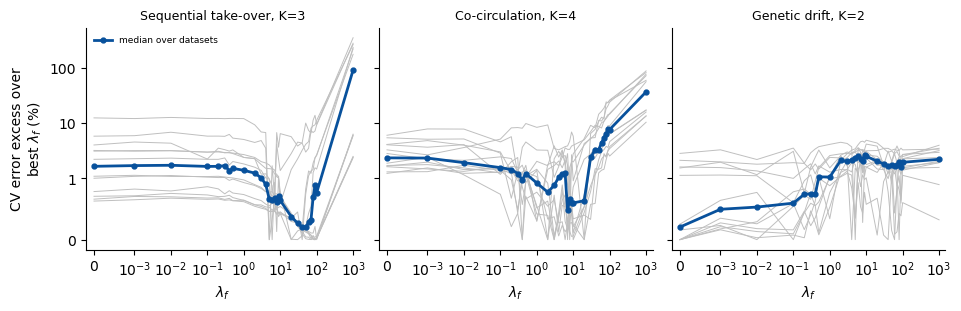

,sim,lambda_f,mean_error,excess
0,disp1_missing_10_delta_replicator,0.000,0.013442,3.213765
1,disp1_missing_10_delta_replicator,0.001,0.013430,3.116722
2,disp1_missing_10_delta_replicator,0.010,0.013436,3.165280
3,disp1_missing_10_delta_replicator,0.100,0.013414,2.998359
4,disp1_missing_10_delta_replicator,0.200,0.013416,3.013758
...,...,...,...,...
1003,disp3_missing_6_omicron_replicator,70.000,0.012895,3.330925
1004,disp3_missing_6_omicron_replicator,80.000,0.012956,3.818365
1005,disp3_missing_6_omicron_replicator,90.000,0.012933,3.636267
1006,disp3_missing_6_omicron_replicator,100.000,0.013060,4.647843


In [13]:
SCEN = [('delta_replicator', 'Sequential take-over, K=3'),
        ('omicron_replicator', 'Co-circulation, K=4'),
        ('genetic_drift', 'Genetic drift, K=2')]

def plot_lambda_f_profile(summ, save=True):
    s = summ.copy()
    s['r'] = s.sim.map(true_rank)
    s = s[s.n_variants == s.r]
    prof = s.groupby(['sim', 'lambda_f'])['mean_error'].min().reset_index()
    prof['excess'] = (prof.mean_error / prof.groupby('sim')['mean_error'].transform('min') - 1) * 100
    b = s.loc[s.groupby('sim')['mean_error'].idxmin()]
    se_rel = b.std_error / np.sqrt(10) / b.mean_error * 100         # std over folds / sqrt(K), K = 10

    fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.0), sharey=True, constrained_layout=True)
    for ax, (scen, title) in zip(axes, SCEN):
        p = prof[prof.sim.str.endswith('_' + scen)]
        for sim, g in p.groupby('sim'):
            ax.plot(g.lambda_f, g.excess, color='0.75', lw=0.7)

        med = p.groupby('lambda_f')['excess'].median()
        ax.plot(med.index, med.values, color='#08519c', lw=2, marker='o', ms=3.5, label='median over datasets')

        ax.set_xscale('symlog', linthresh=1e-3); ax.set_yscale('symlog', linthresh=1)
        ax.set_xlim(-2e-4, 1500); ax.set_title(title, fontsize=9); ax.set_xlabel(r'$\lambda_f$')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('CV error excess over\nbest $\\lambda_f$ (%)')
    axes[0].set_yticks([0, 1, 10, 100]); axes[0].set_yticklabels(['0', '1', '10', '100'])
    axes[0].legend(frameon=False, fontsize=6.5, loc='upper left')
    if save:
        fig.savefig('../results/cross_validation_results/simulations/cv_error_vs_lambda_f_simulate.pdf', bbox_inches='tight')
    plt.show()
    return prof
plot_lambda_f_profile(summ)

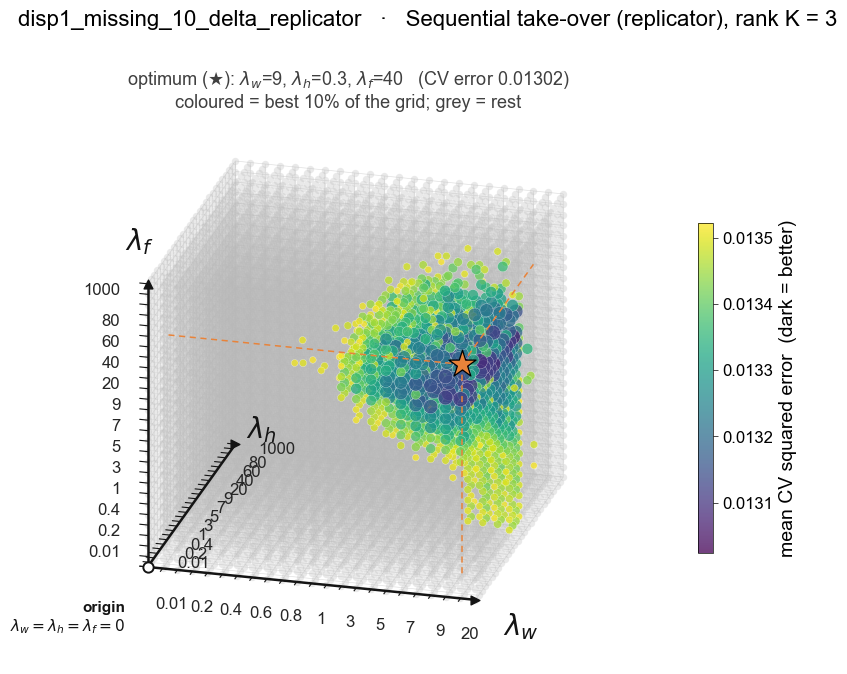

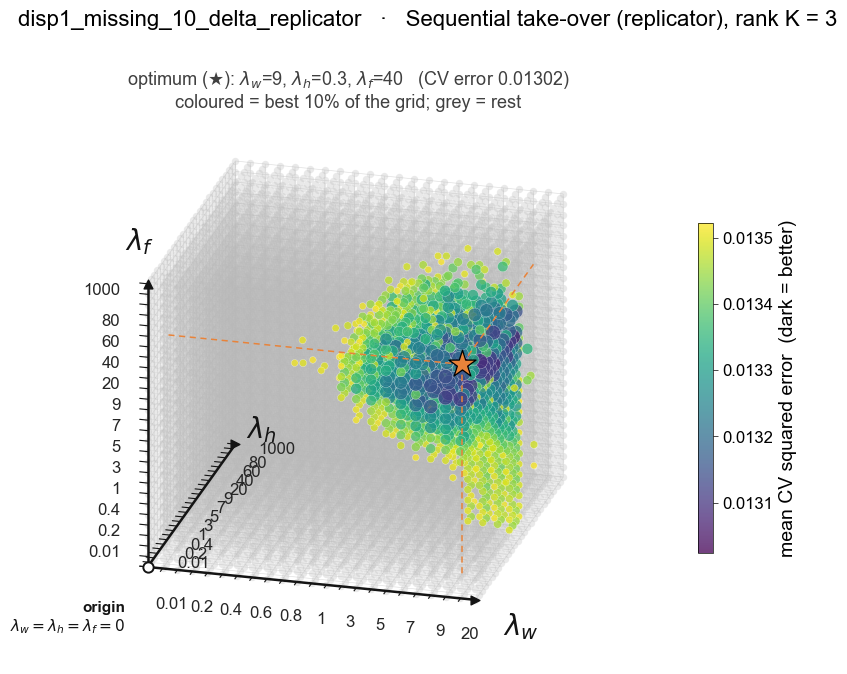

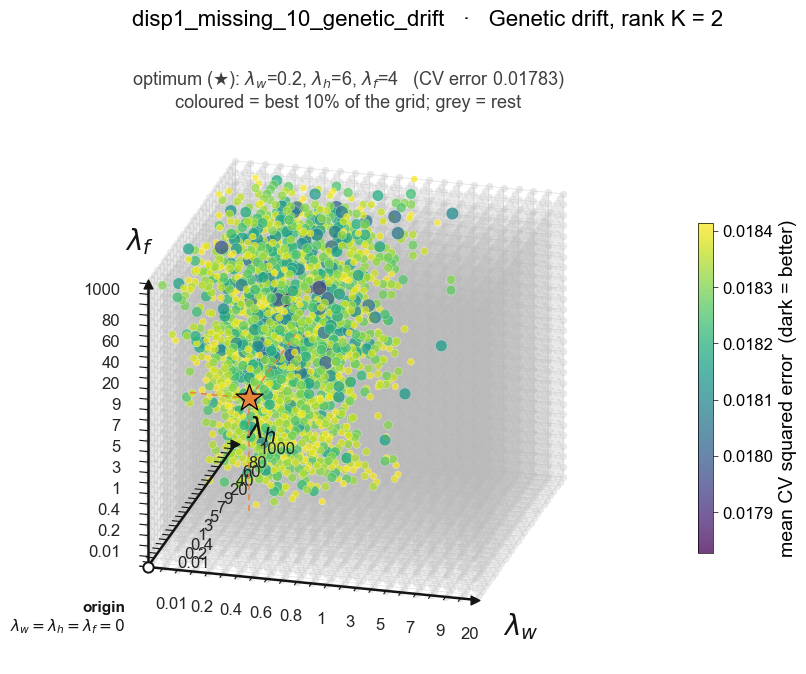

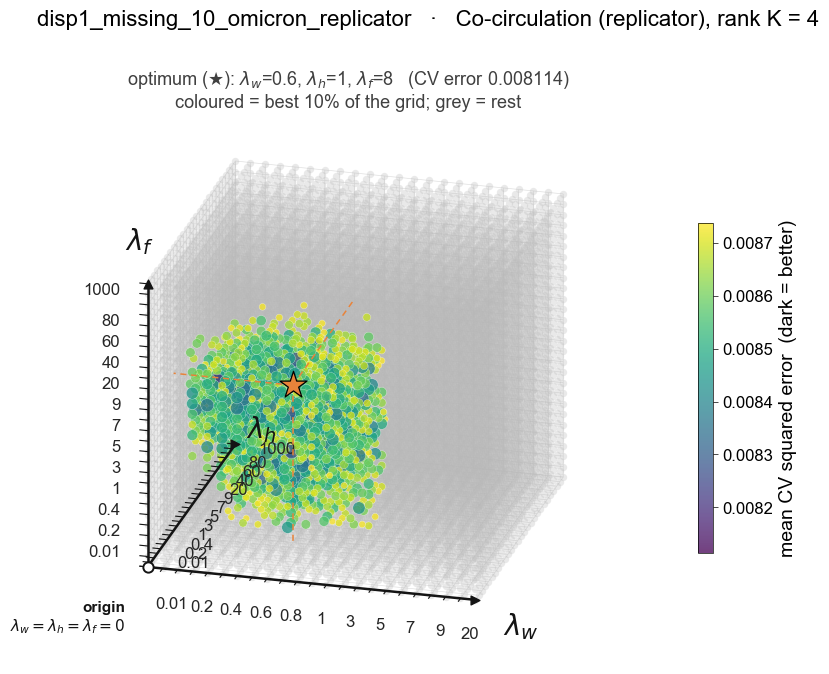

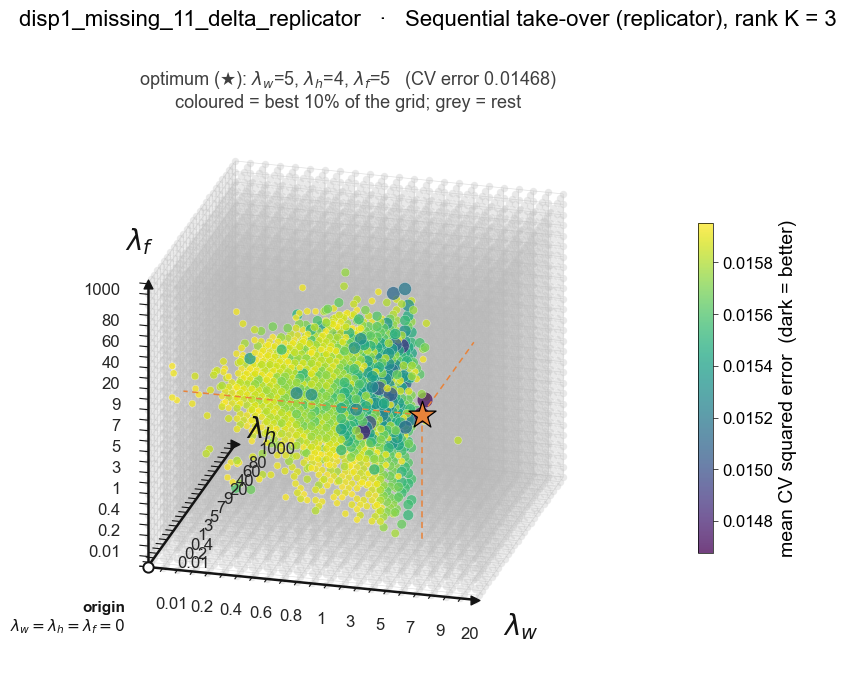

...

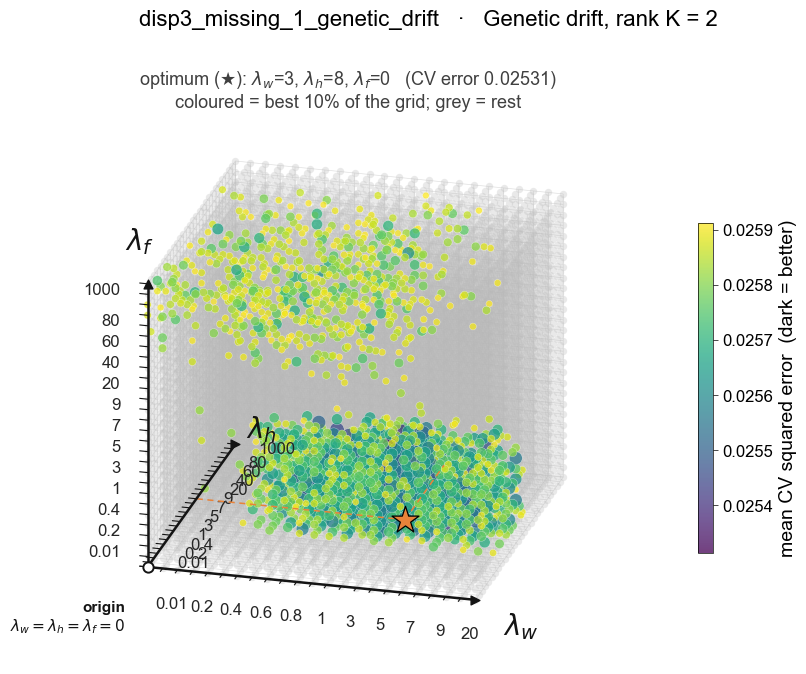

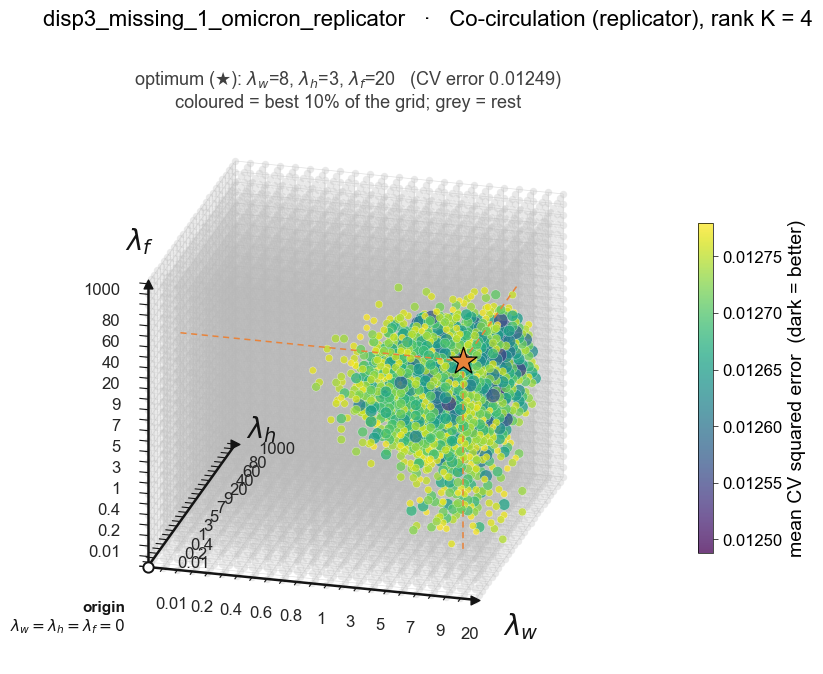

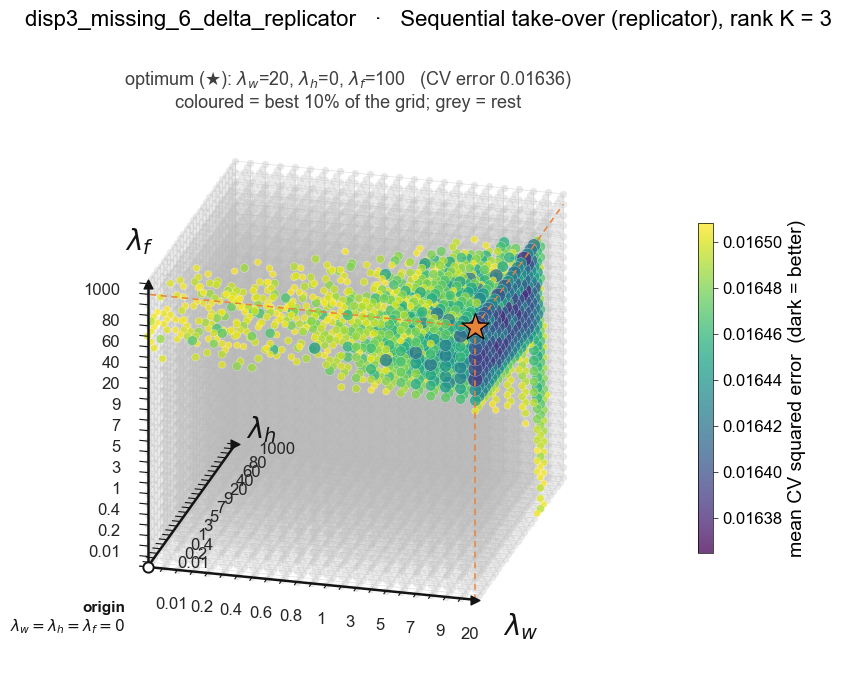

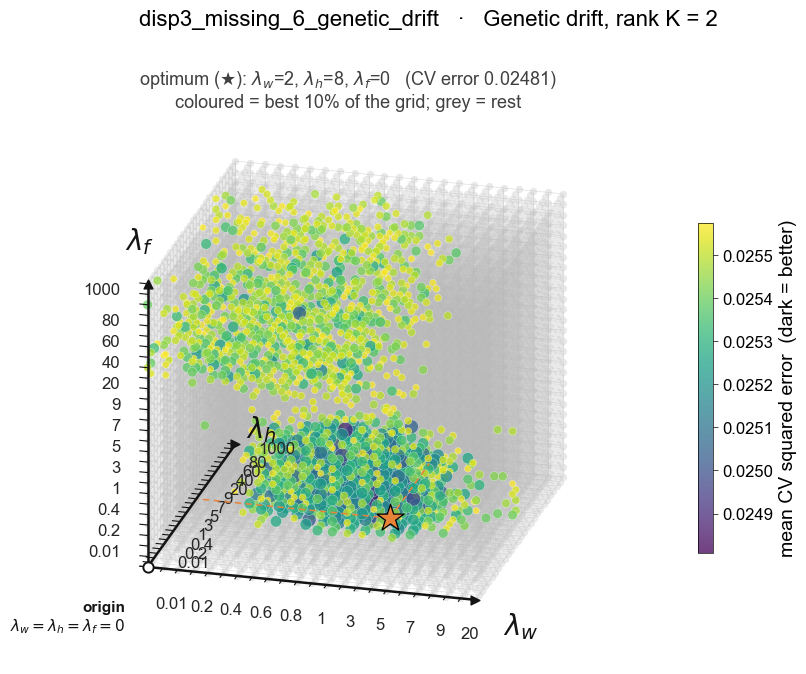

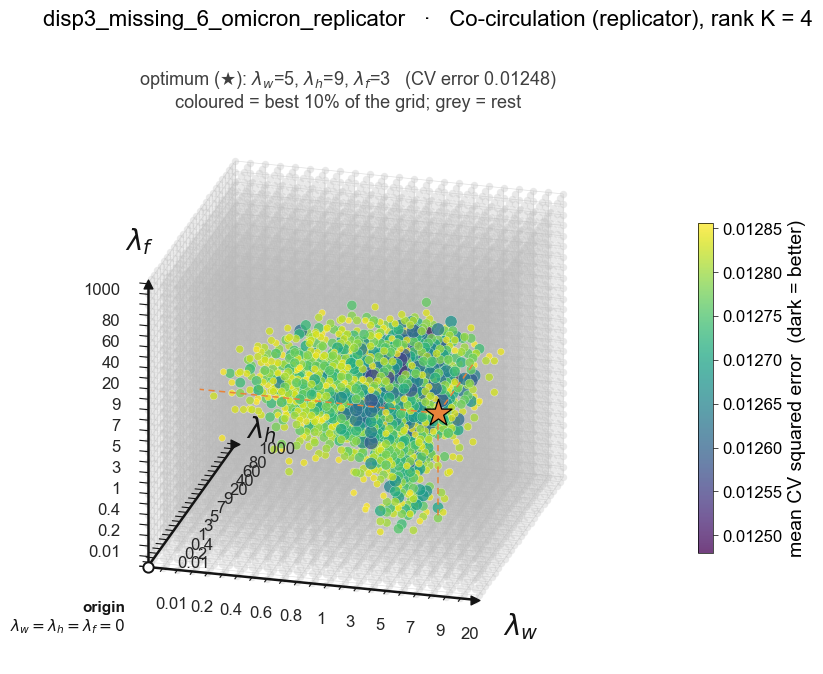

In [15]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

ORANGE = '#E8833A'
TRUE_RANK = {'delta': 3, 'omicron': 4, 'drift': 2}
PRETTY = {'delta': 'Sequential take-over (replicator)', 'omicron': 'Co-circulation (replicator)', 'drift': 'Genetic drift'}

# ── font sizes (change here) ─────────────────────────────────────────────────
FS_TICK   = 12     # lambda values along the axes
FS_AXIS   = 20     # lambda_w / lambda_h / lambda_f at the arrow tips
FS_ORIGIN = 11     # 'origin' annotation
FS_CBAR   = 14     # colour-bar label
FS_CBTICK = 12     # colour-bar tick labels
FS_SUPT   = 16     # figure title
FS_TITLE  = 13     # optimum line


def true_rank(sim):
    for k, r in TRUE_RANK.items():
        if k in sim:
            return r
    raise ValueError(f"cannot infer scenario from '{sim}'")


def plot_sim_3d(sim, summ, best_frac=0.10, elev=22, azim=-75, cmap='viridis', save=True, show=True):
    """One 3D plot for all three lambdas at the true rank.
       Axes = lambda_w, lambda_h, lambda_f (grid positions, values as tick labels);
       colour = mean CV error (dark = better); only the best `best_frac` of the grid is coloured,
       the rest are small grey dots; star = best combination."""
    r = true_rank(sim)
    s = summ[(summ.sim == sim) & (summ.n_variants == r)].copy()
    if s.empty:
        raise ValueError(f"{sim}: no results for rank {r}")
    best_row = s.loc[s.mean_error.idxmin()]

    keys = ['lambda_w', 'lambda_h', 'lambda_f']
    vals = {k: sorted(s[k].unique()) for k in keys}
    pos = {k: {v: i for i, v in enumerate(vals[k])} for k in keys}
    X, Y, Z = (s[k].map(pos[k]).to_numpy() for k in keys)
    err = s.mean_error.to_numpy()
    thr = np.quantile(err, best_frac)
    good = err <= thr
    span = max(thr - err.min(), 1e-12)

    with mpl.rc_context({'font.family': 'sans-serif',
                         'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                         'mathtext.fontset': 'dejavusans'}):
        fig = plt.figure(figsize=(9.5, 7.8))
        ax = fig.add_subplot(111, projection='3d', computed_zorder=False)   # honour explicit zorders
        ax.set_proj_type('ortho')

        # context: the rest of the grid as faint dots
        ax.scatter(X[~good], Y[~good], Z[~good], color='0.72', s=28, alpha=0.30,
                   linewidths=0, depthshade=False, zorder=1)
        # best region: colour = CV error, bigger = better
        sc = ax.scatter(X[good], Y[good], Z[good], c=err[good], cmap=cmap, vmin=err.min(), vmax=thr,
                        s=22 + 110 * (thr - err[good]) / span, alpha=0.75,
                        edgecolor='white', linewidths=0.25, depthshade=False, zorder=2)

        # optimum: guide lines to the walls + star on top
        bx, by, bz = (pos[k][best_row[k]] for k in keys)
        gl = dict(ls=(0, (4, 3)), lw=1.1, color=ORANGE, zorder=5)
        ax.plot([bx, 0], [by, by], [bz, bz], **gl)
        ax.plot([bx, bx], [by, len(vals['lambda_h']) - 1], [bz, bz], **gl)
        ax.plot([bx, bx], [by, by], [bz, 0], **gl)
        ax.scatter([bx], [by], [bz], marker='*', s=420, color=ORANGE, edgecolor='black',
                   linewidth=0.9, depthshade=False, zorder=20)

        # ---- explicit coordinate axes that meet at the origin (lambda_w = lambda_h = lambda_f = 0) ----
        n = {k: len(vals[k]) for k in keys}
        ax.set_xlim(0, n['lambda_w'] - 1); ax.set_ylim(0, n['lambda_h'] - 1); ax.set_zlim(0, n['lambda_f'] - 1)
        for st_, sl_, k_ in [(ax.set_xticks, ax.set_xticklabels, 'lambda_w'), (ax.set_yticks, ax.set_yticklabels, 'lambda_h'),
                             (ax.set_zticks, ax.set_zticklabels, 'lambda_f')]:
            st_(range(n[k_])); sl_([''] * n[k_])                           # keep grid lines, drop matplotlib's labels
        ax.tick_params(length=0)
        for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):
            a_.set_pane_color((1, 1, 1, 0)); a_._axinfo['grid'].update(color='0.88', linewidth=0.5)
            a_.line.set_visible(False)
        L = dict(color='0.08', lw=1.8, solid_capstyle='round', zorder=6)
        ax.plot([0, n['lambda_w'] - 1], [0, 0], [0, 0], **L)
        ax.plot([0, 0], [0, n['lambda_h'] - 1], [0, 0], **L)
        ax.plot([0, 0], [0, 0], [0, n['lambda_f'] - 1], **L)
        # arrow tips
        ax.scatter([n['lambda_w'] - 1], [0], [0], marker='>', s=40, color='0.08', depthshade=False, zorder=6)
        ax.scatter([0], [n['lambda_h'] - 1], [0], marker='>', s=40, color='0.08', depthshade=False, zorder=6)
        ax.scatter([0], [0], [n['lambda_f'] - 1], marker='^', s=40, color='0.08', depthshade=False, zorder=6)
        # origin marker
        ax.scatter([0], [0], [0], marker='o', s=55, color='white', edgecolor='0.08', linewidth=1.4,
                   depthshade=False, zorder=7)
        ox, oy, oz = n['lambda_w'] * 0.045, n['lambda_h'] * 0.045, n['lambda_f'] * 0.045
        # tick labels = real lambda values (every 2nd), written along the axes
        for k, d in [('lambda_w', 0), ('lambda_h', 1), ('lambda_f', 2)]:
            m = n[k]; show_i = (set(range(0, m, 2)) | {m - 1}) - {m - 2}
            for i, v in enumerate(vals[k]):
                p = [0.0, 0.0, 0.0]; p[d] = i
                if i in show_i and i > 0:                 # '0' is written once, at the origin
                    off = [0.0, 0.0, 0.0]
                    if d == 0: off = [0, -oy * 1.4, -oz * 1.4]
                    if d == 1: off = [ox * 1.5, 0, -oz * 0.2]
                    if d == 2: off = [-ox * 1.4, -oy * 1.4, 0]
                    ax.text(p[0] + off[0], p[1] + off[1], p[2] + off[2], f"{v:g}", fontsize=FS_TICK,
                            ha={0: 'center', 1: 'left', 2: 'right'}[d], va='top' if d == 0 else 'center', color='0.15')
                # small tick mark on the axis
                t = [p[:], p[:]]
                if d == 0: t[1][1] -= oy * 0.5
                if d == 1: t[1][0] -= ox * 0.5
                if d == 2: t[1][0] -= ox * 0.5
                ax.plot([t[0][0], t[1][0]], [t[0][1], t[1][1]], [t[0][2], t[1][2]], color='0.08', lw=0.8, zorder=6)
        # axis names at the arrow tips
        ax.text(n['lambda_w'] - 1 + ox * 1.8, 0, -oz * 1.8, r'$\lambda_w$', fontsize=FS_AXIS, ha='left', va='center', color='0.08')
        ax.text(0, n['lambda_h'] - 1 + oy * 2.6, 0, r'$\lambda_h$', fontsize=FS_AXIS, ha='left', va='center', color='0.08')
        ax.text(-ox * 0.5, 0, n['lambda_f'] - 1 + oz * 2.0, r'$\lambda_f$', fontsize=FS_AXIS, ha='center', va='bottom', color='0.08')
        ax.set_box_aspect((1, 1, 0.9))
        ax.view_init(elev=elev, azim=azim)
        for a_ in (ax.xaxis, ax.yaxis, ax.zaxis):                           # no stray matplotlib tick marks
            a_._axinfo['tick']['inward_factor'] = 0; a_._axinfo['tick']['outward_factor'] = 0
        from mpl_toolkits.mplot3d import proj3d
        x2, y2, _ = proj3d.proj_transform(0, 0, 0, ax.get_proj())
        ax.annotate('origin\n$\\lambda_w=\\lambda_h=\\lambda_f=0$', xy=(x2, y2), xycoords='data', xytext=(-16, -24),
                    textcoords='offset points', ha='right', va='top', fontsize=FS_ORIGIN, color='0.08', fontweight='bold')

        cb = fig.colorbar(sc, ax=ax, shrink=0.55, aspect=22, pad=0.10)
        cb.set_label('mean CV squared error  (dark = better)', fontsize=FS_CBAR)
        cb.outline.set_linewidth(0.5); cb.ax.tick_params(labelsize=FS_CBTICK, width=0.5)

        scen = [v for k, v in PRETTY.items() if k in sim][0]
        fig.suptitle(f"{sim}   ·   {scen}, rank K = {r}", fontsize=FS_SUPT, y=0.98)
        ax.set_title(f"optimum ($\\bigstar$): $\\lambda_w$={best_row.lambda_w:g}, $\\lambda_h$={best_row.lambda_h:g}, "
                     f"$\\lambda_f$={best_row.lambda_f:g}   (CV error {best_row.mean_error:.4g})\n"
                     f"coloured = best {best_frac:.0%} of the grid; grey = rest", fontsize=FS_TITLE, color='0.25', pad=-30)
        if save:
            #fig.savefig(f"cv3d_{sim}_rank{r}.png", dpi=300, bbox_inches='tight')
            fig.savefig(f"../results/cross_validation_results/simulations/cv3d_{sim}_rank{r}.pdf", bbox_inches='tight')
        if show:
            plt.show()
    return best_row


if __name__ == '__main__':
    summ = simulated_data_cv.rename(columns={'location': 'sim'}).dropna(subset=['mean_error'])
    for sim in sorted(summ.sim.unique()):
        plot_sim_3d(sim, summ)